# SARS-CoV-2 variants - How fast does the virus evolve?

Viruses are not immune to mutations and evolution.
During the pandemic, the SARS-CoV-2 virus mutated, evolved, and changed its characteristics, leaving us with various new strains and variants.


The evolution of new strains is tied to their rate of mutation.
Therefore, we must know how fast they mutate to understand their evolution.
Their mutation rate is meaningless without some references; thus, we will compare it to the rate of mutations of other viruses.
Apart from the rate, the location of mutations is vital for evolving new characteristics while preserving their viability.
Some specific mutations give rise to a new variant, and we will be interested in where those mutations happen in different variants.
Lastly, we will focus on Australia and its variant landscape throughout the pandemic.

#### Please ensure each answer is completed in the single cell of the notebook immediately following the question, and that all answers are in ```markdown``` format.

Once you have completed the notebook, make sure you save it and submit it via Moodle.

All questions are worth between 3 and 10 marks. There are a total of *40 marks* available in this workbook. There is an extra bonus problem for *5 marks*. 
  
Total notebook marks will be scaled to a **course mark out of 10** to contribute to your course total.

In [182]:
import numpy as np          
import pandas as pd         # for saving classification in P4
from Bio import SeqIO       # for reading fasta files

## Problem 1: Rate of mutation

How fast is the SARS-CoV-2 virus evolving? Can we empirically determine the speed of mutation? We can! Most biologists are very meticulous with their experiments and carefully document when samples are collected. We can then take a bunch of viral genomes, select a reference genome (usually the first known occurrence of the virus), and calculate the number of mutations from the reference to the remaining viral genomes. We can then use this information in conjunction with the sample collection dates to estimate how fast the viruses are evolving.

**Task:**
Implement the `jukes_cantor` function in `helper_functions.py` to calculate the genetic distance using Hamming distance and Jukes-Cantor correction. Note that Jukes-Cantor correction ignores insertions and deletions, so when calculating the length of the sequence, you should ignore positions with indels. As a hint, JC corrected and non-corrected genetic distance (ignoring indels) for SARS-CoV-2 sequences should be fairly similar and have the same unit.

Example:
```
AGGT-GA
AGC-AGA
```
This alignment has non-corrected genetic distance (ignoring indels) equal to 1, while JC corrected genetic distance is 1.163.

You have 211 SARS-CoV-2 genomes aligned to the reference (_NC_045512.2_).
You can find their collection date and country in their fasta description (`data/p1-sars-cov-2-variants.fasta`).

Find the first collected instance of SARS-CoV-2, i.e., the virus, with the earliest collection date. We'll use our NCBI reference (_NC_045512.2_) as a reference virus. Make sure to download the reference from the NCBI.
You can use a pandas function `pd.to_datetime()` to convert collection dates into a Timestamp. Timestamps without the explicit day of the month will convert into the first day of the month.

Calculate the JC corrected genetic distance from the reference sequence to all other and plot its dependence on the time elapsed from this starting point.

Create a scatterplot of viruses, where you put genetic distance on the y-axis and time in days (the number of days since the starting point) on your x-axis. The earliest sequence should be located at the origin (0, 0).
Estimate the mutation rate using linear regression and overlay your plot with the regression line.

Mutation rate is the number of mutations divided by the elapsed time. We consider mutations per genome and also per nucleotide. If the above example are two sequences one day apart, then the mutation rate **per genome per day** is 1.163 and mutation rate **per nucledtide per day** is 0.2326. Think about the meaning of these numbers and why we need both of them.

Report the mutation rate per genome per day and save it into the `sars_cov_2_per_genome_per_day` variable. 
Report the mutation rate per nucleotide per day and save it into the `sars_cov_2_per_nt_per_day` variable. 
Save the resulting figure into `problem1.svg`.


Then answer the following question about Jukes-Cantor corrrection:
- Describe why we need the JC correction and why we can’t use raw distances.

Save your answers in the variable `need_for_JC_correction`, respectively.

Hint: check out `np.polyfit` to fit the linear regression curve. Include your reference in the linear fit and account for the intersection when plotting your fit.

**[10 points]** 


In [183]:
sars_cov_2_per_genome_per_day = 0.0748
sars_cov_2_per_nt_per_day = 2.50e-06

In [184]:
from Bio import Entrez
Entrez.email = "z5498942@student.unsw.edu.au"

Example check: 1.163
Loaded NC_045512.2: 29903 nt
Earliest collection date: 2019-12-01
Mutation rate: 0.0748 mutations / genome / day
Mutation rate: 2.501e-06 mutations / nucleotide / day


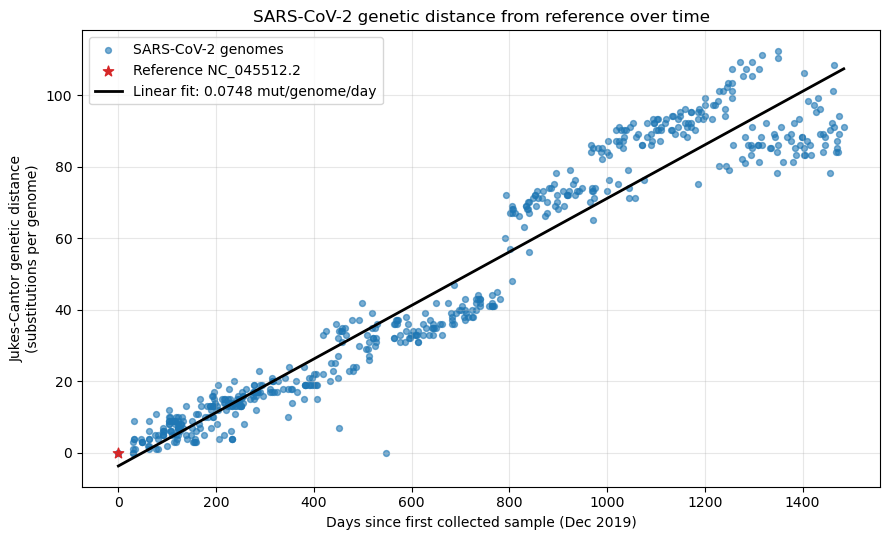

In [185]:
import math
import matplotlib.pyplot as plt


def jukes_cantor(reference_sequence: str, distant_sequence: str) -> float:
    """Jukes-Cantor corrected genetic distance (same unit as Hamming distance, i.e. per genome)."""
    # Keep only positions where both sequences have a determined nucleotide
    # (skips indels "-" and ambiguous/unsequenced bases such as "N")
    valid = set("ACGTU")
    pairs = [(a, b) for a, b in zip(reference_sequence.upper(), distant_sequence.upper())
             if a in valid and b in valid]
    length = len(pairs)
    if length == 0:
        return 0.0
    mismatches = sum(1 for a, b in pairs if a != b)
    if mismatches == 0:
        return 0.0
    p = mismatches / length
    arg = 1 - 4 / 3 * p
    if arg <= 0:
        return float("inf")
    d = -0.75 * math.log(arg)          # substitutions per site
    return d * length                  # substitutions per genome


print("Example check:", round(jukes_cantor("AGGT-GA", "AGC-AGA"), 3))   # should be 1.163

# Reference genome downloaded from NCBI (NC_045512.2, Wuhan-Hu-1)
ncbi_reference = SeqIO.read("data/sequence.fasta", "fasta")
genome_length = len(ncbi_reference.seq)                      # 29903 nt
print(f"Loaded {ncbi_reference.id}: {genome_length} nt")

# Load aligned genomes; header format: ID|country|collection date
p1_records = list(SeqIO.parse("data/p1-sars-cov-2-variants.fasta", "fasta"))
p1_ids = [rec.id.split("|")[0] for rec in p1_records]
p1_seqs = [str(rec.seq) for rec in p1_records]
p1_dates = pd.to_datetime([rec.id.split("|")[2] for rec in p1_records], format="mixed")

# Aligned copy of the reference (same coordinates as the other genomes)
ref_idx = p1_ids.index("NC_045512.2")
ref_seq = p1_seqs[ref_idx]

# Starting point = earliest collected sample (the reference, Dec-2019)
start_date = p1_dates.min()
print("Earliest collection date:", start_date.date())
p1_days = np.array([(d - start_date).days for d in p1_dates])

# JC-corrected distance from the reference to every genome (reference -> 0)
p1_dist = np.array([jukes_cantor(ref_seq, s) for s in p1_seqs])

# Linear regression, reference included
slope, intercept = np.polyfit(p1_days, p1_dist, 1)
print(f"Mutation rate: {slope:.4f} mutations / genome / day")
print(f"Mutation rate: {slope / genome_length:.3e} mutations / nucleotide / day")

# Plot
fig, ax = plt.subplots(figsize=(9, 5.5))
other = np.arange(len(p1_ids)) != ref_idx
ax.scatter(p1_days[other], p1_dist[other], s=18, alpha=0.6, color="tab:blue", label="SARS-CoV-2 genomes")
ax.scatter(p1_days[ref_idx], p1_dist[ref_idx], s=60, color="tab:red", marker="*", zorder=3,
           label="Reference NC_045512.2")
xs = np.linspace(0, p1_days.max(), 200)
ax.plot(xs, slope * xs + intercept, color="black", lw=2,
        label=f"Linear fit: {slope:.4f} mut/genome/day")
ax.set_xlabel("Days since first collected sample (Dec 2019)")
ax.set_ylabel("Jukes-Cantor genetic distance\n(substitutions per genome)")
ax.set_title("SARS-CoV-2 genetic distance from reference over time")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("problem1.svg")
plt.show()

In [186]:
need_for_JC_correction = """
The raw (Hamming / p-) distance only counts the differences we can see today so it underestimates how many
substitutions actually happened. Over time, the same site can be hit more than once: it can mutate and then
mutate again (A->G->T is seen as one difference), mutate back to the original base (A->G->A is seen as zero),
or two lineages can independently reach the same base (parallel mutations). These multiple hits are invisible
in the raw count. Since there are only four nucleotides, two unrelated random sequences still match at about
25% of sites which is why the raw distance saturates at p = 0.75 and stops growing linearly with time even though
mutations keep accumulating.

The Jukes-Cantor model assumes every base mutates to each of the other three at the same rate and corrects for
these hidden substitutions with d = -3/4 ln(1 - 4/3 p). For small p, it is almost the same as the raw distance
(as for SARS-CoV-2, where p is about 0.003) but the correction grows as p increases and goes to infinity as p
approaches 0.75. This gives an estimate of the true number of substitutions that grows roughly linearly with
time, which is what we need to estimate a mutation rate from a regression slope. It also lets us compare
viruses fairly because without it the more diverged viruses such as Ebola and Zika would be underestimated much
more than slowly diverging ones.
"""

## Problem 2: Mutation rate in other viruses

We've estimated the regression slope to SARS-CoV-2. Now what? Does the plot indicate a fast mutation rate? Or a slow mutation rate? Or an average mutation rate? We really can only tell with a frame of reference. In this exercise, we will look at two more viruses from recent outbreaks, the Zaire ebolavirus, and Zika virus, and determine their mutation rate. These will help us get a sufficient reference for the speed at which viruses mutate.

**Task:**
Find the aligned sequences for Ebola and Zika virus in the `data/p2-ebola-viruses.fasta` and `data/p2-zika-viruses.fasta`.
Use the first viral genomes in files as the reference, as these are the earliest known and sequenced viruses.
Follow the same procedure as in Problem 1 to estimate the slope of the regression line. 

Since these viruses have been around longer than SARS-CoV-2, they are more diverse, and the distances between them may be longer.
We observe this if the reference sequence is at the origin, but the others start much higher, i.e., the line fitting the remaining viruses doesn't go through the origin but is shifted higher up.
In this case, ignore the reference sequence when fitting the regression lines.

Report the genome and nucleotide rate of mutation of both viruses and save them into their corresponding variables (`ebola_per_genome_per_day`, `ebola_per_nt_per_day` and `zika_per_genome_per_day`, `zika_per_nt_per_day`).

Then answer the following questions:
- Why did we ignore the reference when fitting the regression line? Keep in mind that in our biological interpretation, this is not an outlier in the machine learning sense. _Hint: think about what assumption are we making when using the reference in the regression fit_.
- When comparing mutation rates between different viruses, should we compare them on a per genome or a per nucleotide basis? Why?

Save your answers in the variables `reference_in_regression` and `comparing_mutation_rates`, respectively.

**[7 points]**


**Why did we choose these two reference viruses?** SARS-CoV-2 is in a unique position where it is a worldwide phenomenon and warranted a global response in the past. As such, SARS-CoV-2 is most likely the most well-documented and tracked virus of all time. Even five years ago, sequencing on this scale would have been impossible. This creates a problem when we want to compare the mutation rate with other viruses. We need reference viruses that have gone through a similar lifecycle to SARS-CoV-2 and need to be recent enough such that sufficient sequencing data is available to estimate the slopes correctly. Unfortunately for us (but thankfully for humanity), only a handful of viruses fit this description (https://en.wikipedia.org/wiki/List_of_epidemics). Additionally, some developing countries still need the technological or economic capability to carry out this kind of sequencing on a large scale, making reliable data challenging to come by. We have chosen the Ebola virus and Zika virus, as their sequencing data is more or less reliable and plentiful enough.

In [187]:
ebola_per_genome_per_day = 0.0364
ebola_per_nt_per_day = 1.96e-06

zika_per_genome_per_day = 0.0345
zika_per_nt_per_day = 3.25e-06

Ebola: 0.0364 mutations / genome / day, 1.959e-06 mutations / nt / day (genome length 18560)
Zika:  0.0345 mutations / genome / day, 3.249e-06 mutations / nt / day (genome length 10612)


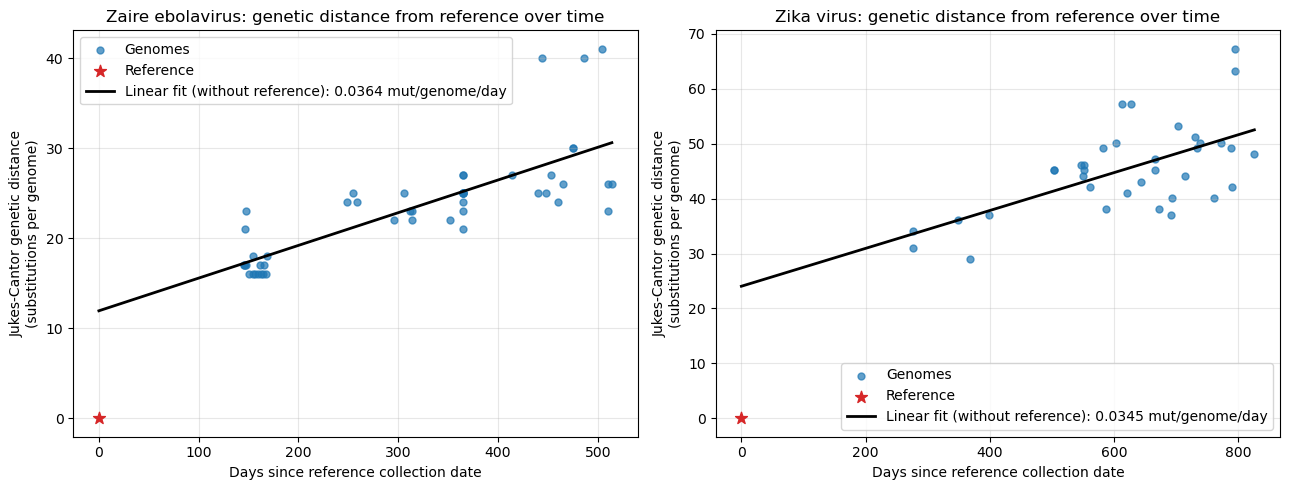

In [188]:
import matplotlib.pyplot as plt


def mutation_rate(fasta_path):
    """JC distances from the first (reference) genome vs. days since its collection date.
    Fits the regression line WITHOUT the reference."""
    records = list(SeqIO.parse(fasta_path, "fasta"))
    seqs = [str(rec.seq) for rec in records]
    # use .description (not .id) because country names like "Sierra Leone" contain spaces
    dates = pd.to_datetime([rec.description.split("|")[2] for rec in records], format="mixed")

    ref_seq = seqs[0]                                  # first genome = earliest known = reference
    genome_length = len(ref_seq.replace("-", ""))      # reference genome length without gaps
    days = np.array([(d - dates[0]).days for d in dates])
    dist = np.array([jukes_cantor(ref_seq, s) for s in seqs])

    slope, intercept = np.polyfit(days[1:], dist[1:], 1)   # reference excluded from the fit
    return days, dist, slope, intercept, genome_length


ebola_days, ebola_dist, ebola_slope, ebola_intercept, ebola_len = mutation_rate("data/p2-ebola-viruses.fasta")
zika_days, zika_dist, zika_slope, zika_intercept, zika_len = mutation_rate("data/p2-zika-viruses.fasta")

print(f"Ebola: {ebola_slope:.4f} mutations / genome / day, "
      f"{ebola_slope / ebola_len:.3e} mutations / nt / day (genome length {ebola_len})")
print(f"Zika:  {zika_slope:.4f} mutations / genome / day, "
      f"{zika_slope / zika_len:.3e} mutations / nt / day (genome length {zika_len})")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name, days, dist, slope, intercept in [
        (axes[0], "Zaire ebolavirus", ebola_days, ebola_dist, ebola_slope, ebola_intercept),
        (axes[1], "Zika virus", zika_days, zika_dist, zika_slope, zika_intercept)]:
    ax.scatter(days[1:], dist[1:], s=25, alpha=0.7, color="tab:blue", label="Genomes")
    ax.scatter(days[0], dist[0], s=80, color="tab:red", marker="*", zorder=3, label="Reference")
    xs = np.linspace(0, days.max(), 200)
    ax.plot(xs, slope * xs + intercept, color="black", lw=2,
            label=f"Linear fit (without reference): {slope:.4f} mut/genome/day")
    ax.set_title(f"{name}: genetic distance from reference over time")
    ax.set_xlabel("Days since reference collection date")
    ax.set_ylabel("Jukes-Cantor genetic distance\n(substitutions per genome)")
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig("problem2.svg")
plt.show()

In [189]:
reference_in_regression = """
Why did we ignore the reference when fitting the regression line? Keep in mind that in our biological interpretation, this is not an outlier in the machine learning sense.

Including the reference in the fit assumes that the reference is the common ancestor of all other sampled
viruses, i.e. that at time 0 the genetic distance is 0 and every later genome descended from it by
accumulating mutations along a straight line. That holds for SARS-CoV-2, where the reference was sampled at
the very start of the outbreak. Ebola and Zika, on the other hand hass been circulating and diversifying for a long
time before these outbreaks. The reference is just one earlier sampled strain, not the ancestor of the later
genomes. The later outbreak strains split off from a common ancestor with the reference well before the
reference was sampled which is why even the earliest of them are already ~17 (Ebola) and ~30 (Zika) substitutions
away from it. The point (0, 0) is therefore a real, correct data point, but it lies on a different lineage
and does not follow the same linear trend. Forcing the line through it would greatly overestimate the slope
(e.g. Ebola 0.040 instead of 0.036 and Zika 0.047 instead of 0.034 mutations/genome/day). Excluding it, the
slope measures how fast the outbreak lineage keeps accumulating mutations over time and the intercept
absorbs the pre-existing divergence between the reference and the outbreak strains.
"""

In [190]:
comparing_mutation_rates = """
When comparing mutation rates between different viruses, should we compare them on a per genome or a per nucleotide basis? Why?

We should compare them on a per nucleotide basis. The per genome rate depends on genome length: a longer
genome accumulate more mutations per day simply because it has more sites that can mutate even if each
site mutates at the same speed. SARS-CoV-2 (~29.9 kb), Ebola (~18.9 kb) and Zika (~10.8 kb) have very
different genome lengths, so per genome rates are not comparable. Dividing by genome length gives the
substitution rate per site, which is independent of genome size and reflects the intrinsic speed of
evolution (replication fidelity, selection, etc.). For example, per genome SARS-CoV-2 (0.075) looks about
twice as fast as Zika (0.034), but per nucleotide Zika (3.2e-6) is actually faster than SARS-CoV-2 (2.5e-6),
with Ebola the slowest (2.0e-6 mutations/nt/day).
"""

## Problem 3: Reinterpreting mutation rates

Majority of RNA viral genomes are single-stranded RNA, where only one strand of the viruses encode for the genes. We divide these viruses into positive-sense and negative-sense viruses, based on where they code for genes.
Positive-sense RNA directly codes for genes and acts like mRNA, meaning it can be directly used by the host's ribosomes to make proteins.
Negative-sense RNA is a reverse complement of the positive-sense RNA and does not code for genes directly. It must first be converted into positive-sense RNA by the virus's own enzymes before it can be used to make proteins.
Positive-sense RNA viruses mutate faster because their replication process is simpler and mostly lacks error correction. Negative-sense RNA viruses, on the other hand, mutate more slowly since they have an extra step in replication and require more functional genes to support replication.

Answer the following questions about mutation rates based on the sense-type of the viruses:
- What type of sense (positive or negative) are Zika, Ebola and SARS-CoV-2? Search the web or NCBI.
- How does the mutation rate of SARS-CoV-2, based on its sense-type, compare to another virus with the same sense-type in our three examples? Specifically, is SARS-CoV-2 mutating faster or slower than that virus?
- Is there a molecular mechanism of SARS-CoV-2 that explains the answer above?

Save your answers in the variables `sense_types_of_viruses`, `sars_cov_2_faster_slower` and `mutation_molecular_mechanism`, respectively.

**[3 points]** 

In [191]:
sense_types_of_viruses = """
What type of sense (positive or negative) are Zika, Ebola and SARS-CoV-2? Search the web or NCBI.

Zika virus: positive-sense single-stranded RNA virus (+ssRNA), family Flaviviridae.
Ebola virus (Zaire ebolavirus): negative-sense single-stranded RNA virus (-ssRNA), family Filoviridae.
SARS-CoV-2: positive-sense single-stranded RNA virus (+ssRNA), family Coronaviridae.
So Zika and SARS-CoV-2 are positive-sense, and Ebola is negative-sense.
"""

In [192]:
sars_cov_2_faster_slower = """
How does the mutation rate of SARS-CoV-2, based on its sense-type, compare to another virus with the same sense-type in our three examples? Specifically, is SARS-CoV-2 mutating faster or slower than that virus?

SARS-CoV-2 should be compared with Zika, the other positive-sense RNA virus in our examples, using the per
nucleotide rates (genome lengths differ). SARS-CoV-2 mutate at about 2.50e-6 substitutions/nt/day, whereas
Zika mutates at about 3.25e-6 substitutions/nt/day. The SARS-CoV-2 is mutating SLOWER than Zika (roughly 25%
slower per site). In fact, it is much closer to the negative-sense Ebola virus (about 1.96e-6
substituutions/nt/day), which is unexpected for a positive-sense RNA virus. (Per genome SARS-CoV-2 look faster,
0.075 vs 0.034 mutations/genome/day, but only because its genome is almost three times longer.)
"""

In [193]:
mutation_molecular_mechanism = """
Is there a molecular mechanism of SARS-CoV-2 that explains the answer above?

Yes. Coronaviruses, including SARS-CoV-2, are unusual among RNA viruses because they have a proofreading
enzyme. Non-structural protein 14 (nsp14) contains a 3'-to-5' exoribonuclease (ExoN) domain that, together
with its cofactor nsp10, associates withh the RNA-dependent RNA polymerase (nsp12) replication complex. It
recognises and removes mismatched nucleotides that the polymerase has wrongly added at the 3' end of the
newly synthesised RNA, so the error is corrected before replication continues. This increases replication
fidelity and lowers the mutation rate. Most other RNA viruses, including Zika, lack such a proofreading
activity, so their polymerase errors remain as mutations. Proofreading is thought to be what allows
coronaviruses to maintain their very large RNA genomes (~30 kb) which would otherwise accumulate too many
harmful mutations. This explains why SARS-CoV-2 mutates more slowly per nucleotide than Zika despite both being
positive-sense RNA viruses.
"""

## Problem 4: Variant-specific mutations

As the virus mutates, it inevitably evolves and proliferates around the world. Every so often, some mutations may prove especially beneficial to the spread of the virus, and this version of the virus spreads faster than other versions. When a version of a virus becomes especially prevalent inside a population, we call this a virus *variant*. Variants are nothing more than a naming scheme for viruses that have specific mutations. For instance, in Slovenia during 2022, we were dealing with the Omicron variant. Think of this as observing natural selection in real time. Some viruses have mutations that enable them to spread more easily throughout our population, which inevitably leads to the demise of other virus variants, which are not as good at proliferation. The result is survival of the fittest at the viral level, where, unfortunately, the fittest viruses seem to cause the most damage to us humans.

How do we identify variants? A variant is determined by several so-called *defining mutations*. Mutations can either be synonymous or nonsynonymous. Synonymous mutations are changes in nucleotide bases that result in the same encoded amino acid and are thus less important. Nonsynonymous mutations are nucleotide mutations that alter the amino acid sequence of a protein.

To determine mutations, we first have to select a reference genome, which we will say has no mutations. In most cases, this is the first known occurrence of the virus, but in our case, the reference NCBI genome from Wuhan in 2019 (_NC_045512.2_).
Then, we align each viral genome of interest to this reference genome. All the differences between the reference genome and the genome of interest are said to be mutations.

To get a sense of the distribution of mutations across the genome in a variant, we will observe the most common mutations in **Alpha** (20I (Alpha, V1)) and **Delta** (21A (Delta)) variants. We will then try to answer whether the Delta variant emerged from the Alpha variant or evolved independently from a different strain of the virus.

**Task:**
Use pre-aligned sequences from the file `data/p1-sars-cov-2-variants.fasta`. To facilitate indexing, the reference sequence in the alignment has no indels. Extract the Alpha and Delta variants according to the indices in lists `alpha_variants` and `delta_variants`, respectively.

Calculate the nucleotide mismatches between each sequence and the reference sequence for the variant. Then, compute the average mismatch ratio for each nucleotide position to generate an array of mutation frequencies ranging from 0 to 1. A value of 0 means no mutations occurred at that position in any sequence, while a value of 1 indicates that all sequences have a mutation at that position relative to the reference. Ensure that mutations are calculated separately for each variant.

Plot the mutation occurrences across the whole genome for the Alpha and Delta variants separately on one figure (two subplots, one on top of another). Represent the mutation occurance as a line plot (_ax.plot_ or _plt.plot_) were x-axis is sequence index and y-axis is the average mutation occurance. Show only the part of the genome above the 20000 nucleotides and mark locations of the SARS-CoV-2 genes (with colors and labels). You can find gene locations in the `gene_locations` variable. Expect a few sites with occurrence one and the rest close to zero.

We say a mutation is vital if its occurrence is higher than 0.5. Find all vital mutations in the spike gene ("S") and compare results between variants. There are a few sites where both variants mutated, but only one where the same mutation occurred.

Store your plot in the `problem3.svg` and make it visually appealing.
Find indices of each site on the S gene where mutations occurred in both variants. Store integer sites into a `mutations_in_both_variants` variable where the site refers to the nucleotide in the reference genome.
Store the only same mutation into the `same_mutation` variable as a string denoting reference nucleotide, mutation site, and the variant nucleotide (e.g. "G123A", where G on position 123 in the reference mutates into an A.)


Then answer the following questions:
- Did the Delta variant evolve from the Alpha variant? Explain your reasoning based on the common mutations.

Save your answers in the variable `alpha_from_delta`, respectively.

**[10 points]**

In [194]:
gene_locations = {
    'S': (21462, 25284),
    'E': (26144, 26372),
    'M': (26422, 27091),
    'N': (28173, 29433)
}

alpha_variants  = ["EPI_ISL_3072041","EPI_ISL_1010703","EPI_ISL_1121977","EPI_ISL_1061036","EPI_ISL_1184096",
                   "EPI_ISL_1184504","EPI_ISL_3568432","EPI_ISL_3568427","EPI_ISL_1184097","EPI_ISL_1447289",
                   "EPI_ISL_1615593","EPI_ISL_1660402","EPI_ISL_1660401","EPI_ISL_2404987","EPI_ISL_2462429", 
                   "EPI_ISL_593696"]

delta_variants =  ["EPI_ISL_1904460", "EPI_ISL_1904466", "EPI_ISL_1904469", "EPI_ISL_1904454", "EPI_ISL_1756027", 
                   "EPI_ISL_2404986", "EPI_ISL_2107448", "EPI_ISL_2107529", "EPI_ISL_2650457", "EPI_ISL_2716414", 
                   "EPI_ISL_2633525", "EPI_ISL_2786933", "EPI_ISL_2811809", "EPI_ISL_2695796", "EPI_ISL_2650470", 
                   "EPI_ISL_2811992", "EPI_ISL_2695794", "EPI_ISL_2695799", "EPI_ISL_3281261", "EPI_ISL_3186692",
                   "EPI_ISL_3186471", "EPI_ISL_3186636", "EPI_ISL_3186262", "EPI_ISL_3186487", "EPI_ISL_3280996", 
                   "EPI_ISL_3305513", "EPI_ISL_3072100", "EPI_ISL_6757593", "EPI_ISL_3426420", "EPI_ISL_3539677", 
                   "EPI_ISL_4055434", "EPI_ISL_3834282", "EPI_ISL_3643716", "EPI_ISL_3501929", "EPI_ISL_5535311", 
                   "EPI_ISL_3502476", "EPI_ISL_3502311", "EPI_ISL_3834174", "EPI_ISL_9964573", "EPI_ISL_4747964",
                   "EPI_ISL_4205585", "EPI_ISL_4552276", "EPI_ISL_4205719", "EPI_ISL_4205539", "EPI_ISL_5689721", 
                   "EPI_ISL_4205197", "EPI_ISL_4552130", "EPI_ISL_4747905", "EPI_ISL_5347813", "EPI_ISL_5534640", 
                   "EPI_ISL_5936432", "EPI_ISL_5778590", "EPI_ISL_5534654", "EPI_ISL_5778467", "EPI_ISL_5778492", 
                   "EPI_ISL_6252077", "EPI_ISL_5535134", "EPI_ISL_5305653", "EPI_ISL_7264600", "EPI_ISL_6585779", 
                   "EPI_ISL_6586228", "EPI_ISL_6251927", "EPI_ISL_6585956", "EPI_ISL_7264849", "EPI_ISL_6586173", 
                   "EPI_ISL_6586136", "EPI_ISL_7264591", "EPI_ISL_6757382", "EPI_ISL_7621131", "EPI_ISL_7621166", 
                   "EPI_ISL_8901286", "EPI_ISL_7748984", "EPI_ISL_7621531", "EPI_ISL_7621692", "EPI_ISL_7621124", 
                   "EPI_ISL_7748623", "EPI_ISL_7748687", "EPI_ISL_7621974", "EPI_ISL_8901160", "EPI_ISL_10116719", 
                   "EPI_ISL_8901318", "EPI_ISL_8901337", "EPI_ISL_10116652", "EPI_ISL_8900986", "EPI_ISL_8901124",
                   "EPI_ISL_8901168", "EPI_ISL_8901097", "EPI_ISL_10116931"] 

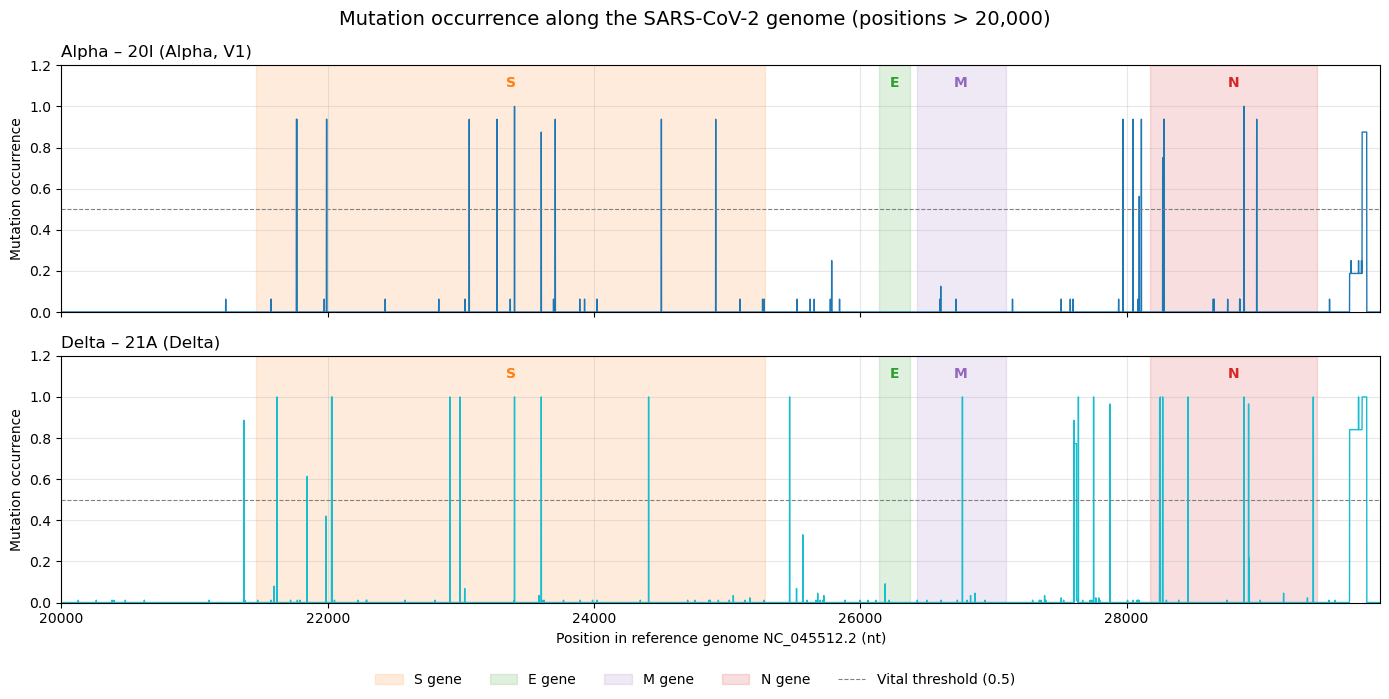

Alpha vital S mutations: ['T21765-', 'A21766-', 'C21767-', 'A21768-', 'T21769-', 'G21770-', 'T21991-', 'T21992-', 'A21993-', 'A23063T', 'C23271A', 'A23403G', 'C23604A', 'C23709T', 'T24506G', 'G24914C']
Delta vital S mutations: ['C21618G', 'C21846T', 'A22029-', 'G22030-', 'T22031-', 'T22032-', 'C22033-', 'A22034-', 'T22917G', 'C22995A', 'A23403G', 'C23604G', 'G24410A']
Sites mutated in both variants: [23403, 23604]
  site 23403: Alpha A23403G, Delta A23403G <- same mutation
  site 23604: Alpha C23604A, Delta C23604G 


In [195]:
import matplotlib.pyplot as plt

# Load the aligned genomes into a dictionary: accession id -> sequence
p4_seqs = {rec.description.split("|")[0]: str(rec.seq).upper()
           for rec in SeqIO.parse("data/p1-sars-cov-2-variants.fasta", "fasta")}
ref_arr = np.array(list(p4_seqs["NC_045512.2"]))


def mutation_frequency(ids):
    """Fraction of sequences with a mutation (substitution or deletion) at each reference position.
    Unknown bases (N and other ambiguity codes) are not counted as mutations."""
    M = np.array([list(p4_seqs[i]) for i in ids])
    mutated = (M != ref_arr) & np.isin(M, list("ACGT-"))
    mutated[:, ref_arr == "-"] = False           # masked ends of the reference
    return mutated.mean(axis=0), M


alpha_freq, alpha_M = mutation_frequency(alpha_variants)
delta_freq, delta_M = mutation_frequency(delta_variants)

# Plot 
gene_colors = {"S": "tab:orange", "E": "tab:green", "M": "tab:purple", "N": "tab:red"}
positions = np.arange(1, len(ref_arr) + 1)       # 1-based reference positions
start_plot = 20000

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, name, freq, color in [(axes[0], "Alpha – 20I (Alpha, V1)", alpha_freq, "tab:blue"),
                              (axes[1], "Delta – 21A (Delta)", delta_freq, "tab:cyan")]:
    for gene, (start, end) in gene_locations.items():
        ax.axvspan(start, end, color=gene_colors[gene], alpha=0.15, label=f"{gene} gene")
        ax.text((start + end) / 2, 1.08, gene, ha="center", va="bottom",
                fontweight="bold", color=gene_colors[gene])
    ax.plot(positions[start_plot:], freq[start_plot:], color=color, lw=1)
    ax.axhline(0.5, color="grey", ls="--", lw=0.8, label="Vital threshold (0.5)")
    ax.set_ylim(0, 1.2)
    ax.set_xlim(start_plot, len(ref_arr))
    ax.set_ylabel("Mutation occurrence")
    ax.set_title(name, loc="left")
    ax.grid(alpha=0.3)
handles, labels = axes[0].get_legend_handles_labels()
axes[1].set_xlabel("Position in reference genome NC_045512.2 (nt)")
fig.suptitle("Mutation occurrence along the SARS-CoV-2 genome (positions > 20,000)", fontsize=14)
fig.legend(handles, labels, loc="lower center", ncol=5, frameon=False)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig("problem3.svg")
plt.show()

# Vital mutations (occurrence > 0.5) on the S gene 
s_start, s_end = gene_locations["S"]


def most_common_base(M, i):
    bases, counts = np.unique(M[:, i], return_counts=True)
    return bases[np.argmax(counts)]


def vital_in_S(freq, M):
    return {i + 1: f"{ref_arr[i]}{i + 1}{most_common_base(M, i)}"       # 1-based site
            for i in range(s_start, s_end) if freq[i] > 0.5}


alpha_S = vital_in_S(alpha_freq, alpha_M)
delta_S = vital_in_S(delta_freq, delta_M)
print("Alpha vital S mutations:", list(alpha_S.values()))
print("Delta vital S mutations:", list(delta_S.values()))

both_sites = sorted(set(alpha_S) & set(delta_S))
print("Sites mutated in both variants:", both_sites)
for site in both_sites:
    print(f"  site {site}: Alpha {alpha_S[site]}, Delta {delta_S[site]}",
          "<- same mutation" if alpha_S[site] == delta_S[site] else "")

In [196]:
mutations_in_both_variants = [23403, 23604]
same_mutation = "A23403G"

In [197]:
alpha_from_delta="""
Did the Delta variant evolve from the Alpha variant? Explain your reasoning based on the common mutations.

No, the Delta variant did not evolve from the Alpha variant. They evolved independently from an earlier
common ancestor. On the S gene the two variants share only two mutated sites:

1. A23403G (spike D614G) is the only identical mutation. It is not specific to Alpha. It appeared very early
   in the pandemic (early 2020, lineage B.1) and quickly spread worldwide, so almost all later lineages,
   including both Alpha and Delta, inherited it from their common ancestor.
2. At site 23604 both variants mutated, but to different nucleotides. C23604A in Alpha (P681H) and C23604G in
   Delta (P681R). If Delta descended from Alpha, it would carry Alpha's A at this position. Instead, the same
   codon (P681, next to the furin cleavage site) was hit independently, which is convergent evolution driven
   by a selective advantage (better spike cleavage and transmissibility) not inheritance.

Furthermore, all the other defining Alpha spike mutations are absent from Delta: the deletions at 21765-21770
(H69/V70 del) and 21991-21993 (Y144 del), A23063T (N501Y), C23271A (A570D), C23709T (T716I), T24506G (S982A)
and G24914C (D1118H). Delta instead has its own set (C21618G T19R, the 22029-22034 deletion E156/F157,
T22917G L452R, C22995A T478K, G24410A D950N). If Delta had evolved from Alpha, it would have kept most of
Alpha's defining mutations. So Alpha and Delta are separate lineages that both branched off from the early
D614G-carrying B.1 lineage.
"""

## Problem 5: Identifying variants

As we've seen, mutations are not distributed uniformly across the genome. Important mutations at specific sites distinguish variants from each other. Nonsynonymous mutations are the ones reflected in the proteins they produce.

A standard convention is to denote mutations using a short string, e.g., *S:T 19 R*. The first part denotes the protein where the mutation has occurred. The second part is comprised of the actual mutation. For instance, *S:T 19 R* means that we are looking at a mutation on the S -- spike protein, where the original amino acid at location 19 was T -- threonine, which changed to R -- arginine. The "-" symbol indicates a deletion (e.g., *S:H 69 -*). For a complete reference of SARS-CoV-2 mutations, you can take a look at https://covariants.org and look through the different variants. We will not consider insertions in this homework, as it would only complicate our lives. Note that location of aminoacids in proteins start with 1 and not 0 like in python notation.

In this part of the assignment, we will take a handful of SARS-CoV-2 genomes from Australia and look at how the different variants spread throughout our country over time.
We will focus on the spike protein sequence as this will speed up computation.
Additionally, the spike protein sequence is the most interesting in terms of variants, as mutations on the spike protein directly affect its ability to spread throughout our population and potentially get around our vaccination efforts.

**Task**

You have 665 pre-aligned SARS-CoV-2 spike protein sequences collected from Australia at various time points (`data/p5-aus-spike-proteins.fasta`). Your job is to determine the variant of each spike protein sequence. We have also prepared a JSON file (*variants.json*) containing all the information on SARS-CoV-2 variants that you'll need. Use the variant names and nonsynonymous mutations defined in this file for your classification. We have removed some of the variants for the purposes of this assignment.

Your task is to look through each of the provided SARS-Cov-2 sequences and assign it to a variant.
To assign a variant, count the number of corresponding mutations on the spike protein sequence. Note that mutation locations start with index 1 in the _variants.json_ file.
Assign the variant to a sequence with the highest percentage of matching mutations to a given variant. If you do not get at least 51% match for any of the variants, you should assign the genome to the *UNKNOWN* class. If a sequence has no mutations throughout the whole genome compared to the reference, assign it to the *NO_MUTATIONS* class. Make sure to check for ALL mutations, not just the ones in the dictionary. If there is a tie, assign whichever variant. Save your answers to `problem5-classification.csv`. This file should contain two columns. The first column should indicate the accession id, e.g., *EPI_ISL_635200*, while the second column should indicate the variant display name (as specified in variants.json), e.g., *20I (Alpha, V1)* or *21K (Omicron)*. The CSV file should have no header. **[5 points]**

After you have assigned all the sequences to a variant, create a plot showing the change in distribution over time. More concretely, we have given you up to 30 sequences per month. Calculate the percentage of each variant in each month, and plot the distribution over time. Your plots should resemble https://covariants.org/per-country, which you can use to validate your work. Note that your plot will probably have a lot of *UNKNOWN* viral assignments. Save your figure into `problem5.svg`. **[5 points]** 

**Hints**:

1. Use [`plt.stackplot`](https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.pyplot.stackplot.html) for plotting. You might also find the pandas [`Grouper`](https://pandas.pydata.org/docs/reference/api/pandas.Grouper.html) class helpful when calculating percentages per month.

2. We will use a function `pd.read_csv("problem5-classification.csv", sep=",", header=None)` to read your classification file, so you can test the correct format.

**Notes**:

1. Due to the fast nature of the sequencing done in these sequences, some sequences may contain the character "X". This character does not denote some new amino acid but means that the sequencing was ambiguous and/or that the amino acid wasn't able to be determined. Ignore any positions with the "X" character, and do not count them toward mutations.

3. Although you could perform the alignment yourself with the algorithms you implemented in part 1, in this exercise, we have already pre-aligned the viral genomes for you to avoid any long-running computation. In this part, we will only consider substitutions and deletions, and we will ignore insertions. Insertions would needlessly complicate mutation indexing. Additionally, almost none of the variants for SARS-CoV-2 are determined by insertions, so we can ignore them.

**[10 points]**

Reference spike length: 1273
variant
UNKNOWN            155
22D (Omicron)      144
21A (Delta)        134
21L (Omicron)      112
22A (Omicron)       49
NO_MUTATIONS        28
22F (Omicron)       17
20I (Alpha, V1)     12
20A/S:439K           4
20H (Beta, V2)       2
21B (Kappa)          2
21C (Epsilon)        2
22E (Omicron)        1
21D (Eta)            1
20J (Gamma, V3)      1
20B/S:732A           1
Name: count, dtype: int64


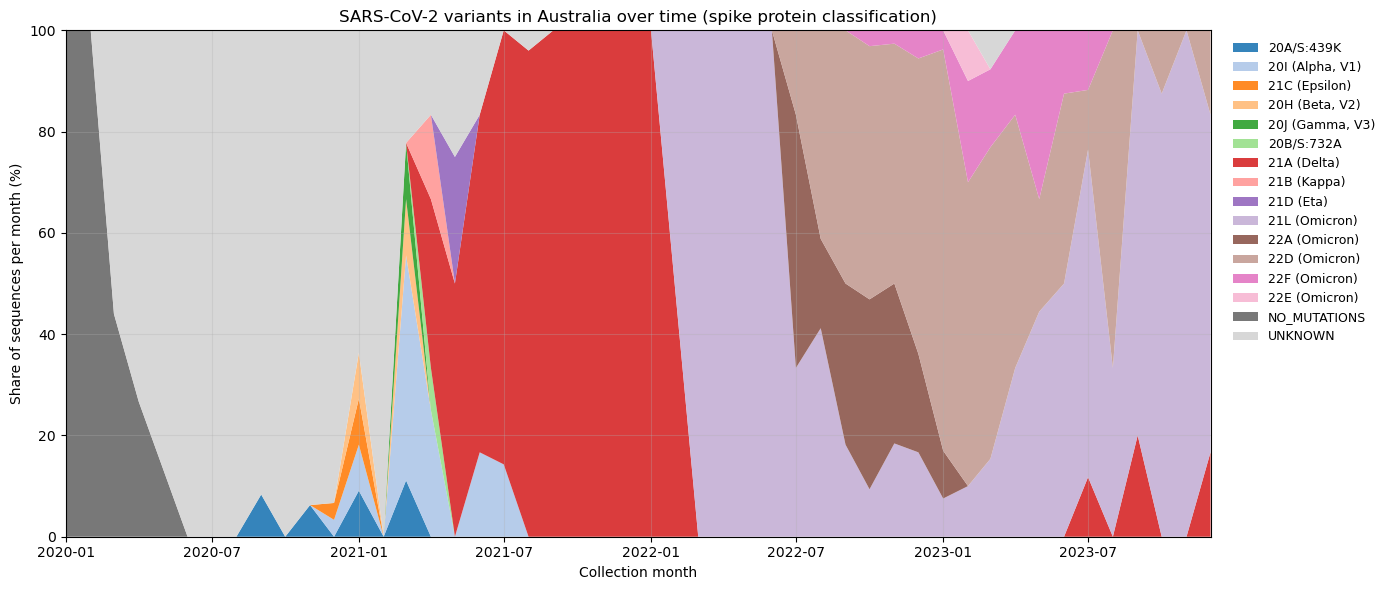

                  0              1
0  EPI_ISL_18798808    21A (Delta)
1  EPI_ISL_18073819    21A (Delta)
2  EPI_ISL_18725264  21L (Omicron)
3  EPI_ISL_18300760    21A (Delta)
4  EPI_ISL_18012233  21L (Omicron)


In [198]:
import json
import matplotlib.pyplot as plt

# Reference spike protein: translate the S gene of NC_045512.2 (nt 21563-25384, 1-based) 
ncbi_reference = SeqIO.read("data/sequence.fasta", "fasta")
ref_spike = str(ncbi_reference.seq[21562:25384].translate(to_stop=True))
print("Reference spike length:", len(ref_spike))           # 1273 aa

# Variant definitions: keep only spike (S) nonsynonymous mutations 
with open("data/variants.json") as f:
    variants = json.load(f)
variant_mutations = {name: [(m["pos"], m["left"], m["right"])
                            for m in info["nonsynonymous"] if m["gene"] == "S"]
                     for name, info in variants.items()}

# Load the Australian spike sequences; header: name|date|accession
p5_records = list(SeqIO.parse("data/p5-aus-spike-proteins.fasta", "fasta"))
p5_ids = [rec.description.split("|")[2] for rec in p5_records]
p5_dates = pd.to_datetime([rec.description.split("|")[1] for rec in p5_records])
p5_seqs = [str(rec.seq) for rec in p5_records]


def classify(seq):
    # any mutation at all (substitution or deletion) compared with the reference, ignoring X
    has_mutation = any(a != r and a != "X" for a, r in zip(seq, ref_spike))
    if not has_mutation:
        return "NO_MUTATIONS"
    best_variant, best_score = "UNKNOWN", 0.0
    for name, muts in variant_mutations.items():
        matched = sum(1 for pos, left, right in muts if seq[pos - 1] == right)   # X never matches
        score = matched / len(muts)
        if score > best_score:
            best_variant, best_score = name, score
    return best_variant if best_score >= 0.51 else "UNKNOWN"


p5_df = pd.DataFrame({"accession": p5_ids, "date": p5_dates,
                      "variant": [classify(s) for s in p5_seqs]})
p5_df[["accession", "variant"]].to_csv("problem5-classification.csv", header=False, index=False)
print(p5_df["variant"].value_counts())

# Percentage of each variant per month 
monthly = (p5_df.groupby([pd.Grouper(key="date", freq="MS"), "variant"]).size()
                .unstack(fill_value=0))
monthly_pct = monthly.div(monthly.sum(axis=1), axis=0) * 100

# order variants by when they first appear; UNKNOWN / NO_MUTATIONS last
order = sorted([v for v in monthly_pct.columns if v not in ("UNKNOWN", "NO_MUTATIONS")],
               key=lambda v: monthly_pct.index[monthly_pct[v] > 0][0])
order += [v for v in ("NO_MUTATIONS", "UNKNOWN") if v in monthly_pct.columns]
monthly_pct = monthly_pct[order]

colors = list(plt.cm.tab20.colors)
color_map = {v: colors[i % len(colors)] for i, v in enumerate(order)}
color_map["UNKNOWN"] = "lightgrey"
color_map["NO_MUTATIONS"] = "dimgrey"

fig, ax = plt.subplots(figsize=(14, 6))
ax.stackplot(monthly_pct.index, monthly_pct.T.values, labels=order,
             colors=[color_map[v] for v in order], alpha=0.9)
ax.set_xlim(monthly_pct.index.min(), monthly_pct.index.max())
ax.set_ylim(0, 100)
ax.set_ylabel("Share of sequences per month (%)")
ax.set_xlabel("Collection month")
ax.set_title("SARS-CoV-2 variants in Australia over time (spike protein classification)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("problem5.svg")
plt.show()

# Check the CSV format the way the marker reads it
print(pd.read_csv("problem5-classification.csv", sep=",", header=None).head())

## Bonus 1: Kimura two-parameter correction (K2P)

Kimura's two-parameter model is a more elaborate approach to correcting genetic distances. It assumes that transitions are four times more likely to occur than transversion, thus weighing those substitutions differently. The model still ignores insertions and deletions.

**Task:**
Implement `kimura_two_parameter` in the `helper_functions.py` to calculate the Kimura correction of genetic distance.
Everything about JC correction still applies here (ignoring indels, output having the same unit, etc.).

Example:
```
AGGT-GA
AGC-AGA
```
This alignment has non-corrected genetic distance (ignoring indels) equal to 1, while Kimura 2P corrected genetic distance is 1.196.

Recalculate the mutation rate for SARS-CoV-2 as in Problem 1, this time with Kimura's corrected distances. Follow the same protocol from Problem 1 and store both mutation rates into their appropriate variables `sars_cov_2_per_genome_per_day_k2p` and `sars_cov_2_per_nt_per_day_k2p`, respectively.

Then answer the following questions about the mutation rates:
- What is the size of the difference between JC-corrected and K2P-corrected distances? Why is this difference particularly small or large in our specific case?
- Does the K2P model's assumption about the ratio of transitions to transversions apply to SARS-CoV-2? Provide the average number of transitions and transversions observed between the reference sequence and other sequences.

Save your answers in the variables `jc_vs_k2p_distances` and `transitions_and_transversions`, respectively.

**[5 points]**

In [199]:
sars_cov_2_per_genome_per_day_k2p = 0.00
sars_cov_2_per_nt_per_day_k2p = 0.00

In [200]:
jc_vs_k2p_distances = """
What is the size of the difference between JC-corrected and K2P-corrected distances? Why is this difference particularly small or large in our specific case?
"""

In [201]:
transitions_and_transversions = """
Does the K2P model's assumption about the ratio of transitions to transversions apply to SARS-CoV-2? Provide the average number of transitions and transversions observed between the reference sequence and other sequences.
"""